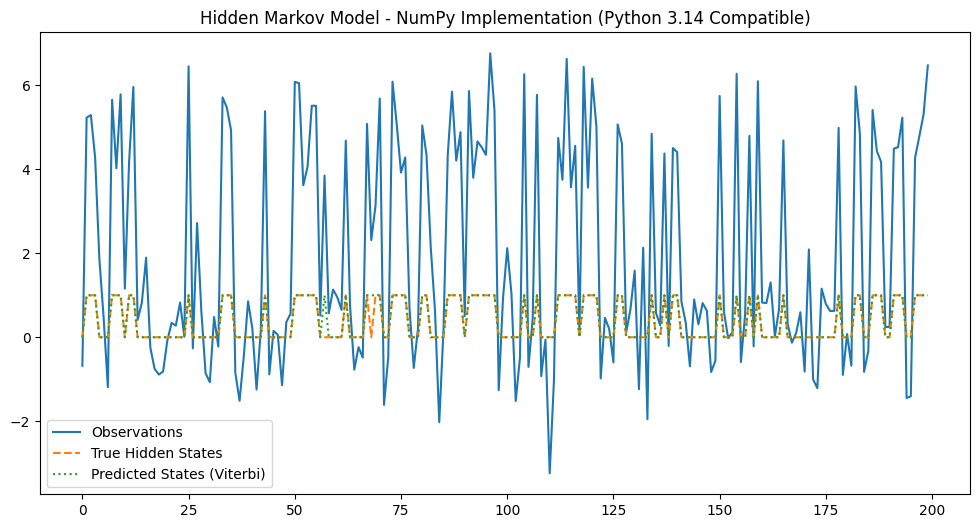

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Number of states
states = ["S1", "S2"]
n_states = len(states)

# Transition matrix
transition_matrix = np.array([
    [0.7, 0.3],
    [0.4, 0.6]
])

# Means and variances for each state's observation distribution
means = [0, 5]
variances = [1, 1]

# Generate sequence length
T = 200

# Generate hidden states
hidden_states = [np.random.choice(n_states, p=[0.6, 0.4])]
for _ in range(1, T):
    prev = hidden_states[-1]
    next_state = np.random.choice(n_states, p=transition_matrix[prev])
    hidden_states.append(next_state)

hidden_states = np.array(hidden_states)

# Generate observations
observations = np.array([
    np.random.normal(means[s], np.sqrt(variances[s])) for s in hidden_states
])

# --- VITERBI ALGORITHM ---
def viterbi(obs, means, vars, trans):
    T = len(obs)
    n_states = len(means)

    # Probabilities
    log_prob = np.zeros((T, n_states))
    path = np.zeros((T, n_states), dtype=int)

    # Initialization
    for s in range(n_states):
        emission = -0.5 * np.log(2 * np.pi * vars[s]) - (obs[0] - means[s])**2 / (2 * vars[s])
        log_prob[0, s] = np.log(0.5) + emission

    # Recursion
    for t in range(1, T):
        for s in range(n_states):
            emission = -0.5 * np.log(2 * np.pi * vars[s]) - (obs[t] - means[s])**2 / (2 * vars[s])
            trans_probs = log_prob[t-1] + np.log(trans[:, s])
            best_prev = np.argmax(trans_probs)
            log_prob[t, s] = trans_probs[best_prev] + emission
            path[t, s] = best_prev

    # Backtracking
    states_seq = np.zeros(T, dtype=int)
    states_seq[-1] = np.argmax(log_prob[-1])
    for t in range(T - 2, -1, -1):
        states_seq[t] = path[t + 1, states_seq[t + 1]]

    return states_seq

predicted_states = viterbi(observations, means, variances, transition_matrix)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(observations, label="Observations")
plt.plot(hidden_states, label="True Hidden States", linestyle="--")
plt.plot(predicted_states, label="Predicted States (Viterbi)", linestyle=":")
plt.legend()
plt.title("Hidden Markov Model - NumPy Implementation (Python 3.14 Compatible)")
plt.show()